<a href="https://colab.research.google.com/github/Jacobzzz0522/3u3-Project-2/blob/main/referring_expression_segmentation_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
!nvidia-smi

Wed Oct 21 23:31:31 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
!pip install -q transformers accelerate
import torch
print(torch.__version__, torch.cuda.is_available())


2.11.0+cu130 True


In [5]:
import numpy as np
from PIL import Image as PILImage, ImageDraw


In [6]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


preprocessor_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.74k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.24k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  933MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1182 [00:00<?, ?it/s]

a couch: 0.71  box=(2,1,636,475)
a cat: 0.46  box=(347,20,636,377)
a cat: 0.50  box=(11,51,318,473)


/usr/local/lib/python3.13/dist-packages/transformers/models/grounding_dino/processing_grounding_dino.py:89: FutureWarning: The key `labels` is will return integer ids in `GroundingDinoProcessor.post_process_grounded_object_detection` output since v4.51.0. Use `text_labels` instead to retrieve string object names.
  warnings.warn(self.message, FutureWarning)


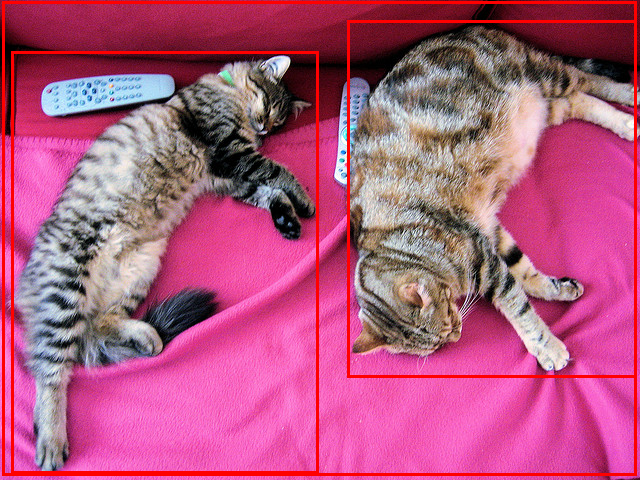

In [7]:
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection
from PIL import Image, ImageDraw
import requests
import torch

# 1. 加载模型
model_id = "IDEA-Research/grounding-dino-base"
processor = AutoProcessor.from_pretrained(model_id)
model = AutoModelForZeroShotObjectDetection.from_pretrained(model_id).to("cuda")
model.eval()

# 2. 下载测试图（两只猫的经典图）
url = "http://images.cocodataset.org/val2017/000000039769.jpg"
image = Image.open(requests.get(url, stream=True).raw).convert("RGB")

# 3. 文字描述 -> 检测框
text_labels = [["a cat", "a couch"]]
inputs = processor(images=image, text=text_labels, return_tensors="pt").to("cuda")
with torch.no_grad():
    outputs = model(**inputs)

results = processor.post_process_grounded_object_detection(
    outputs, inputs.input_ids,
    text_threshold=0.25,
    target_sizes=[image.size[::-1]],
)[0]



# 4. 画框看结果
draw = ImageDraw.Draw(image)
for box, score, label in zip(results["boxes"], results["scores"], results["labels"]):
    x0, y0, x1, y1 = [int(v) for v in box.tolist()]
    draw.rectangle([x0, y0, x1, y1], outline="red", width=3)
    print(f"{label}: {score:.2f}  box=({x0},{y0},{x1},{y1})")
image


processor_config.json:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/683 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/5.71k [00:00<?, ?B/s]

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


model.safetensors: reconstructing file:   0%|          |  0.00B /  898MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/741 [00:00<?, ?it/s]

masks shape: torch.Size([3, 1, 480, 640])


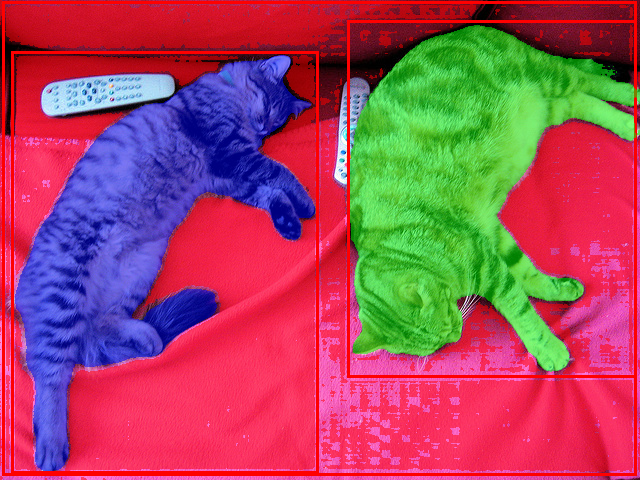

In [8]:
from transformers import Sam2Model, Sam2Processor
import numpy as np

# 1. 加载 SAM 2
sam2_id = "facebook/sam2.1-hiera-large"
sam2_processor = Sam2Processor.from_pretrained(sam2_id)
sam2_model = Sam2Model.from_pretrained(sam2_id).to("cuda")
sam2_model.eval()

# 2. 把 Grounding DINO 的框喂给 SAM 2
boxes = results["boxes"].tolist()          # [[x0,y0,x1,y1], ...] 像素坐标
input_boxes = [boxes]                     # batch → 每张图的框列表
sam_inputs = sam2_processor(images=image, input_boxes=input_boxes, return_tensors="pt").to("cuda")

with torch.no_grad():
    sam_outputs = sam2_model(**sam_inputs, multimask_output=False)

masks = sam2_processor.post_process_masks(
    sam_outputs.pred_masks.cpu(), sam_inputs["original_sizes"]
)[0]
print("masks shape:", masks.shape)

# 3. 可视化：mask 叠加到原图
img_np = np.array(image).copy()
colors = [(255, 0, 0), (0, 255, 0), (0, 0, 255), (255, 255, 0)]
m = masks.squeeze(1).numpy() > 0.5          # (N, H, W) 布尔mask
for i in range(m.shape[0]):
    img_np[m[i]] = (0.5 * img_np[m[i]] + 0.5 * np.array(colors[i % 4])).astype(np.uint8)
Image.fromarray(img_np)


In [9]:
# 1. 加载数据集
!pip install -q datasets
from datasets import load_dataset

ds = load_dataset("lmms-lab-encoder/RefCOCO", split="val")
print(f"val 样本数: {len(ds)}")
print("字段:", ds.column_names)

# 2. 看一条样本
row = ds[0]
print("表达句:", row['answer'])
print("bbox:", row['bbox'])
print("图片尺寸:", row['image'].size)


README.md:   0%|          | 0.00/2.19k [00:00<?, ?B/s]

data/val-00000-of-00004.parquet: reconstructing file:   0%|          |  0.00B /  152MB            

data/val-00000-of-00004.parquet: downloading bytes:           |  0.00B            

data/val-00001-of-00004.parquet: reconstructing file:   0%|          |  0.00B /  217MB            

data/val-00001-of-00004.parquet: downloading bytes:           |  0.00B            

...

Generating val split:   0%|          | 0/8811 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Generating testA split:   0%|          | 0/1975 [00:00<?, ? examples/s]

Generating testB split:   0%|          | 0/1810 [00:00<?, ? examples/s]

val 样本数: 8811
字段: ['question_id', 'image', 'question', 'answer', 'segmentation', 'bbox', 'iscrowd', 'file_name']
表达句: ['bowl behind the others can only see part', 'Dish in top right corner', 'White dish in the top right corner.', 'white pot upper right corner']
bbox: [468.29998779296875, 0.9100000262260437, 171.6999969482422, 116.12000274658203]
图片尺寸: (640, 428)


GT mask: (428, 640) 前景像素: 17897


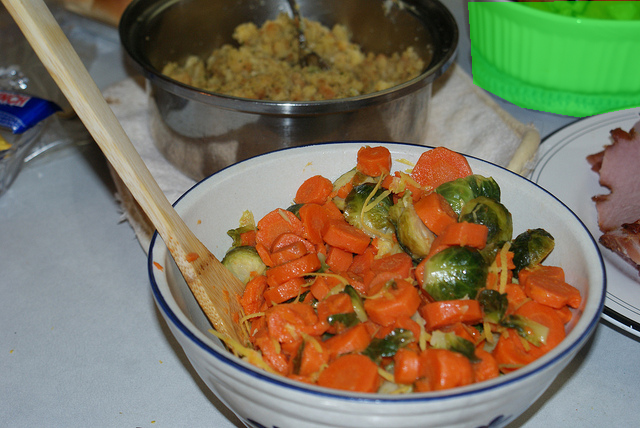

In [10]:
# 3. GT mask：polygon -> 二值图
import numpy as np
from PIL import ImageDraw, Image as PILImage

img = row['image']
mask_img = PILImage.new('L', img.size, 0)
ImageDraw.Draw(mask_img).polygon(row['segmentation'], outline=1, fill=1)
gt_mask = np.array(mask_img) > 0
print("GT mask:", gt_mask.shape, "前景像素:", int(gt_mask.sum()))

# 4. 可视化确认
vis = np.array(img).copy()
vis[gt_mask] = (0.5 * vis[gt_mask] + 0.5 * np.array([0, 255, 0])).astype(np.uint8)
PILImage.fromarray(vis)


表达句: bowl behind the others can only see part
最佳框得分: 0.527
IoU = 0.0000  (交集 0, 并集 49046)


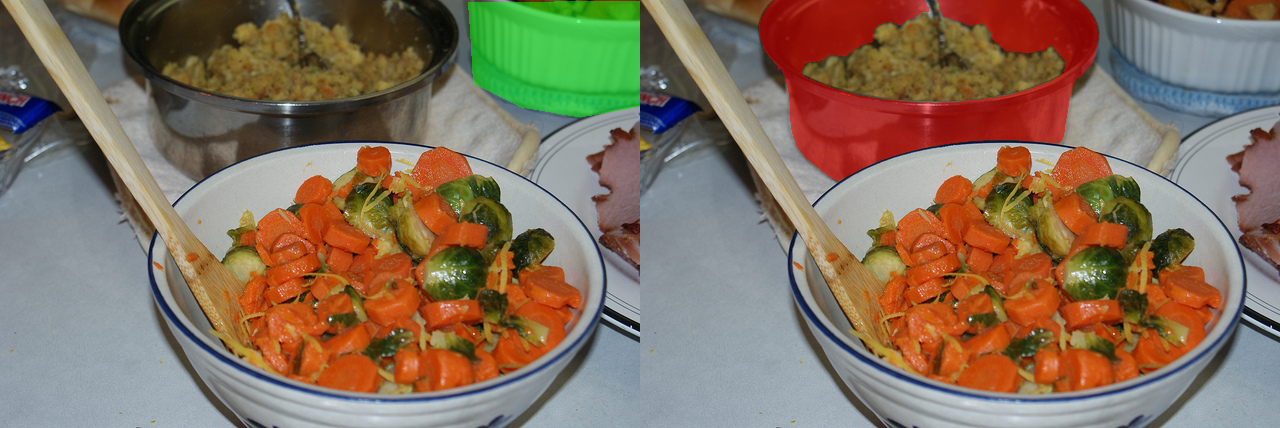

In [11]:
# 6.1 取样本：第一条表达句
row = ds[0]
image = row['image']
expression = row['answer'][0]
print("表达句:", expression)

# 6.2 DINO: 文字 -> 框
inputs = processor(images=image, text=[expression], return_tensors="pt").to("cuda")
with torch.no_grad():
    outputs = model(**inputs)
det = processor.post_process_grounded_object_detection(
    outputs, inputs.input_ids, text_threshold=0.25,
    target_sizes=[image.size[::-1]])[0]

if len(det["boxes"]) == 0:
    print("DINO 没检测到，IoU = 0")
    pred_mask = np.zeros((image.size[1], image.size[0]), dtype=bool)
else:
    best = det["scores"].argmax().item()   # 取置信度最高的框
    box = det["boxes"][best].tolist()
    print(f"最佳框得分: {det['scores'][best]:.3f}")

    # 6.3 SAM2: 框 -> mask
    sam_inputs = sam2_processor(images=image, input_boxes=[[box]], return_tensors="pt").to("cuda")
    with torch.no_grad():
        sam_out = sam2_model(**sam_inputs, multimask_output=False)
    pm = sam2_processor.post_process_masks(sam_out.pred_masks.cpu(), sam_inputs["original_sizes"])[0]
    pred_mask = (pm.squeeze().numpy() > 0.5)

# 6.4 GT mask + IoU
mask_img = PILImage.new('L', image.size, 0)
ImageDraw.Draw(mask_img).polygon(row['segmentation'], outline=1, fill=1)
gt_mask = np.array(mask_img) > 0

inter = np.logical_and(pred_mask, gt_mask).sum()
union = np.logical_or(pred_mask, gt_mask).sum()
iou = inter / union if union > 0 else 0.0
print(f"IoU = {iou:.4f}  (交集 {inter}, 并集 {union})")

# 6.5 并排对比：左=GT(绿)，右=预测(红)
vis_gt = np.array(image).copy()
vis_gt[gt_mask] = (0.5*vis_gt[gt_mask] + 0.5*np.array([0,255,0])).astype(np.uint8)
vis_pred = np.array(image).copy()
vis_pred[pred_mask] = (0.5*vis_pred[pred_mask] + 0.5*np.array([255,0,0])).astype(np.uint8)
PILImage.fromarray(np.concatenate([vis_gt, vis_pred], axis=1))


In [12]:
import time

def predict_mask(image, expression):
    """文字 -> mask；DINO 无检测时返回全零"""
    image = image.convert('RGB')
    inputs = processor(images=image, text=[expression], return_tensors="pt").to("cuda")
    with torch.no_grad():
        outputs = model(**inputs)
    det = processor.post_process_grounded_object_detection(
        outputs, inputs.input_ids, text_threshold=0.25,
        target_sizes=[image.size[::-1]])[0]
    if len(det["boxes"]) == 0:
        return np.zeros((image.size[1], image.size[0]), dtype=bool)
    box = det["boxes"][det["scores"].argmax().item()].tolist()
    sam_inputs = sam2_processor(images=image, input_boxes=[[box]], return_tensors="pt").to("cuda")
    with torch.no_grad():
        sam_out = sam2_model(**sam_inputs, multimask_output=False)
    pm = sam2_processor.post_process_masks(sam_out.pred_masks.cpu(), sam_inputs["original_sizes"])[0]
    return (pm.squeeze().numpy() > 0.5)

def gt_mask_from_row(row):
    m = PILImage.new('L', row['image'].size, 0)
    ImageDraw.Draw(m).polygon(row['segmentation'], outline=1, fill=1)
    return np.array(m) > 0

def iou(a, b):
    inter = np.logical_and(a, b).sum()
    union = np.logical_or(a, b).sum()
    return inter / union if union > 0 else 0.0


In [13]:
import time

def predict_box_mask(image, expression):
    image = image.convert('RGB')
    inputs = processor(images=image, text=[expression], return_tensors="pt").to("cuda")
    with torch.no_grad():
        outputs = model(**inputs)
    det = processor.post_process_grounded_object_detection(
        outputs, inputs.input_ids, text_threshold=0.25,
        target_sizes=[image.size[::-1]])[0]
    h, w = image.size[1], image.size[0]
    if len(det["boxes"]) == 0:
        return None, np.zeros((h, w), dtype=bool)
    box = det["boxes"][det["scores"].argmax().item()].tolist()
    sam_inputs = sam2_processor(images=image, input_boxes=[[box]], return_tensors="pt").to("cuda")
    with torch.no_grad():
        sam_out = sam2_model(**sam_inputs, multimask_output=False)
    pm = sam2_processor.post_process_masks(sam_out.pred_masks.cpu(), sam_inputs["original_sizes"])[0]
    return box, (pm.squeeze().numpy() > 0.5)

def box_to_mask(box, h, w):
    m = np.zeros((h, w), dtype=bool)
    if box is None:
        return m
    x1, y1, x2, y2 = [int(round(v)) for v in box]
    x1, y1 = max(0, x1), max(0, y1)
    x2, y2 = min(w, x2), min(h, y2)
    m[y1:y2, x1:x2] = True
    return m




In [14]:
import time


N = 100
box_ious, mask_ious, failed = [], [], []
t0 = time.time()
for i in range(N):
    try:
        row = ds[i]
        expr = row['answer'][0]
        gt = gt_mask_from_row(row)
        box, pred = predict_box_mask(row['image'], expr)
        box_ious.append(iou(box_to_mask(box, gt.shape[0], gt.shape[1]), gt))
        mask_ious.append(iou(pred, gt))
    except Exception as e:
        failed.append((i, str(e)[:80]))
    if (i + 1) % 20 == 0:
        print(f"{i+1}/{N}  box mIoU: {np.mean(box_ious):.4f}  mask mIoU: {np.mean(mask_ious):.4f}  用时: {time.time()-t0:.0f}s")

def p_at(arr, t):
    return float(np.mean([1.0 if v >= t else 0.0 for v in arr])) if arr else 0.0

print(f"\n有效 {len(mask_ious)}，失败 {len(failed)}")
for name, arr in [('DINO 框 (A)', box_ious), ('DINO+SAM2 (B)', mask_ious)]:
    print(f"{name}: mIoU {np.mean(arr):.4f} | P@0.5 {p_at(arr, 0.5):.3f} | P@0.7 {p_at(arr, 0.7):.3f} | P@0.9 {p_at(arr, 0.9):.3f}")
if failed:
    print("失败样本:", failed[:5])


20/100  box mIoU: 0.4273  mask mIoU: 0.6494  用时: 29s
40/100  box mIoU: 0.4658  mask mIoU: 0.7136  用时: 59s
60/100  box mIoU: 0.4713  mask mIoU: 0.7247  用时: 91s
80/100  box mIoU: 0.4854  mask mIoU: 0.7444  用时: 123s
100/100  box mIoU: 0.4994  mask mIoU: 0.7549  用时: 155s

有效 100，失败 0
DINO 框 (A): mIoU 0.4994 | P@0.5 0.610 | P@0.7 0.160 | P@0.9 0.010
DINO+SAM2 (B): mIoU 0.7549 | P@0.5 0.850 | P@0.7 0.820 | P@0.9 0.410


In [15]:
import json, os, time

RESULTS_PATH = '/content/drive/MyDrive/refcoco_full_eval.jsonl'
START, END = 0, 8811

done = {}
if os.path.exists(RESULTS_PATH):
    with open(RESULTS_PATH) as f:
        for line in f:
            r = json.loads(line)
            done[r['idx']] = r
print(f"账本里已有 {len(done)} 条")

t0 = time.time()
n_run = 0
with open(RESULTS_PATH, 'a') as f:
    for i in range(START, END):
        if i in done:
            continue
        try:
            row = ds[i]
            expr = row['answer'][0]
            gt = gt_mask_from_row(row)
            box, pred = predict_box_mask(row['image'], expr)
            rec = {'idx': i,
                   'box_iou': round(float(iou(box_to_mask(box, gt.shape[0], gt.shape[1]), gt)), 4),
                   'mask_iou': round(float(iou(pred, gt)), 4)}
        except Exception as e:
            rec = {'idx': i, 'error': str(e)[:80]}
        f.write(json.dumps(rec) + '\n')
        f.flush()
        done[i] = rec
        n_run += 1
        if n_run % 50 == 0:
            ok = [r for r in done.values() if 'mask_iou' in r]
            print(f"处理到 {i+1} | 累计有效 {len(ok)} | mask mIoU: {np.mean([r['mask_iou'] for r in ok]):.4f} | 本段用时 {(time.time()-t0)/60:.1f} 分钟")

print("本段结束，账本总条数:", len(done))



账本里已有 8811 条
本段结束，账本总条数: 8811


In [16]:
import json
import numpy as np

RESULTS_PATH = '/content/drive/MyDrive/refcoco_full_eval.jsonl'

recs, bad_lines = {}, 0
for line in open(RESULTS_PATH):
    try:
        r = json.loads(line)
        recs[r['idx']] = r
    except Exception:
        bad_lines += 1

ok = [r for r in recs.values() if 'mask_iou' in r]
errs = sorted([r for r in recs.values() if 'error' in r], key=lambda r: r['idx'])
print(f"总记录 {len(recs)} | 有效 {len(ok)} | 出错 {len(errs)} | 坏行 {bad_lines}")

def p_at(arr, t):
    return float(np.mean([1.0 if v >= t else 0.0 for v in arr])) if arr else 0.0

for name, key in [('DINO 框 (A)', 'box_iou'), ('DINO+SAM2 (B)', 'mask_iou')]:
    arr = [r[key] for r in ok]
    print(f"{name}: mIoU {np.mean(arr):.4f} | P@0.5 {p_at(arr, 0.5):.3f} | P@0.7 {p_at(arr, 0.7):.3f} | P@0.9 {p_at(arr, 0.9):.3f}")

if errs:
    print("\n出错样本（序号 | 报错）:")
    for r in errs:
        print(r['idx'], '|', r['error'])


总记录 8811 | 有效 8811 | 出错 0 | 坏行 0
DINO 框 (A): mIoU 0.4910 | P@0.5 0.576 | P@0.7 0.174 | P@0.9 0.008
DINO+SAM2 (B): mIoU 0.7263 | P@0.5 0.817 | P@0.7 0.757 | P@0.9 0.381


In [17]:
import json
import numpy as np

RESULTS_PATH = '/content/drive/MyDrive/refcoco_full_eval.jsonl'
recs = {}
for line in open(RESULTS_PATH):
    try:
        r = json.loads(line)
        recs[r['idx']] = r
    except Exception:
        pass
ok = [recs[k] for k in sorted(recs) if 'mask_iou' in recs[k]]
mask = np.array([r['mask_iou'] for r in ok])
box = np.array([r['box_iou'] for r in ok])
print(f"有效样本 {len(ok)} 条")

print("\n— mask IoU 分布 —")
print("  == 0       :", int((mask == 0).sum()))
print("  (0, 0.3)   :", int(((mask > 0) & (mask < 0.3)).sum()))
print("  [0.3, 0.5) :", int(((mask >= 0.3) & (mask < 0.5)).sum()))
print("  [0.5, 0.7) :", int(((mask >= 0.5) & (mask < 0.7)).sum()))
print("  [0.7, 0.9) :", int(((mask >= 0.7) & (mask < 0.9)).sum()))
print("  [0.9, 1]   :", int((mask >= 0.9).sum()))

fail = mask < 0.5
print(f"\n— 失败拆解（mask IoU < 0.5，共 {int(fail.sum())} 条）—")
print("  box IoU == 0（DINO 定错位）:", int((box[fail] == 0).sum()))
print("  box IoU > 0 但 mask 仍失败        :", int(((box > 0) & fail).sum()))
print("  其中 box IoU >= 0.5:", int(((box >= 0.5) & fail).sum()))

SPATIAL = ['left', 'right', 'behind', 'front', 'top', 'bottom', 'closest', 'nearest',
           'above', 'below', 'middle', 'corner', 'next to']
exprs = ds['answer']
sp = np.array([any(w in exprs[r['idx']][0].lower() for w in SPATIAL) for r in ok])
print("\n— 空间关系表达 vs 其他 —")
print(f"  含空间词: {int(sp.sum())} 条，失败率 {fail[sp].mean()*100:.1f}%")
print(f"  不含空间词: {int((~sp).sum())} 条，失败率 {fail[~sp].mean()*100:.1f}%")

worst = np.argsort(mask)[:10]
print("\nmask IoU 最低的 10 条 idx:", [ok[i]['idx'] for i in worst])


有效样本 8811 条

— mask IoU 分布 —
  == 0       : 601
  (0, 0.3)   : 719
  [0.3, 0.5) : 294
  [0.5, 0.7) : 524
  [0.7, 0.9) : 3320
  [0.9, 1]   : 3353

— 失败拆解（mask IoU < 0.5，共 1614 条）—
  box IoU == 0（DINO 定错位）: 398
  box IoU > 0 但 mask 仍失败        : 1216
  其中 box IoU >= 0.5: 143

— 空间关系表达 vs 其他 —
  含空间词: 5320 条，失败率 17.7%
  不含空间词: 3491 条，失败率 19.2%

mask IoU 最低的 10 条 idx: [5764, 7330, 7336, 7338, 3830, 6462, 8536, 2658, 2662, 5748]


In [18]:
import os
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

DEMO_DIR = '/content/drive/MyDrive/refcoco_demo'
os.makedirs(DEMO_DIR, exist_ok=True)

def overlay(image, m, color):
    img = np.array(image.convert('RGB')).astype(float)
    c = np.array(color, dtype=float)
    img[m] = img[m] * 0.45 + c * 0.55
    return img.astype(np.uint8)

def make_triptych(idx):
    row = ds[idx]
    expr = row['answer'][0]
    gt = gt_mask_from_row(row)
    box, pred = predict_box_mask(row['image'], expr)
    v = float(iou(pred, gt))
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(row['image'].convert('RGB'))
    if box is not None:
        axes[0].add_patch(Rectangle((box[0], box[1]), box[2]-box[0], box[3]-box[1],
                                    fill=False, edgecolor='yellow', linewidth=2))
    axes[0].set_title(f'"{expr}"'); axes[0].axis('off')
    axes[1].imshow(overlay(row['image'], gt, (0, 255, 0))); axes[1].set_title('Ground Truth'); axes[1].axis('off')
    axes[2].imshow(overlay(row['image'], pred, (255, 0, 0))); axes[2].set_title(f'Prediction (IoU {v:.3f})'); axes[2].axis('off')
    plt.tight_layout()
    plt.savefig(f'{DEMO_DIR}/demo_{idx}.png', dpi=80, bbox_inches='tight')
    plt.close()
    print(idx, 'saved | IoU', round(v, 4))

for idx in [0, 75, 5049]:
    make_triptych(idx)


0 saved | IoU 0.0
75 saved | IoU 0.9345
5049 saved | IoU 0.9775
